In [1]:
# Import library pengolahan citra, machine learning, dan deep learning
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
import pickle

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
# Fungsi pembacaan dataset citra dari direktori folder
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        if not folder.is_dir():
            continue
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            if img is not None:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                img_list.append((img, label))
    return img_list

# Load data training dan testing Day vs Night
train_dir = 'images/training/'
test_dir = 'images/test/'

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f'Jumlah data training: {len(train_img)}')
print(f'Jumlah data testing: {len(test_img)}')

Jumlah data training: 240
Jumlah data testing: 160


In [3]:
# Preprocessing citra: resize ke 256x256 piksel dan encoding label biner
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train_list = preprocess(train_img)
X_test_img, y_test_list = preprocess(test_img)

print(f'Bentuk dimensi citra setelah resize: {X_train_img[0].shape}')
print(f'Total label training: {len(y_train_list)}, label testing: {len(y_test_list)}')

Bentuk dimensi citra setelah resize: (256, 256, 3)
Total label training: 240, label testing: 160


In [4]:
# Ekstraksi fitur bentuk dan tekstur menggunakan HOG (Histogram of Oriented Gradients)
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )
        feats.append(hog_feat)
    return np.array(feats)

print('Mengekstraksi fitur HOG untuk data training dan testing...')
X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

print(f'Dimensi fitur HOG training: {X_train_feat.shape}')
print(f'Dimensi fitur HOG testing: {X_test_feat.shape}')

Mengekstraksi fitur HOG untuk data training dan testing...


Dimensi fitur HOG training: (240, 34596)
Dimensi fitur HOG testing: (160, 34596)


In [5]:
# Normalisasi fitur HOG menggunakan StandardScaler agar mean 0 dan variansi 1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

print(f'Dimensi data training setelah scaling: {X_train_scaled.shape}')
print(f'Dimensi data testing setelah scaling: {X_test_scaled.shape}')

Dimensi data training setelah scaling: (240, 34596)
Dimensi data testing setelah scaling: (160, 34596)


In [6]:
# Split data training menjadi data train dan data validation (80:20)
X_train, X_val, y_train_split, y_val_split = train_test_split(
    X_train_scaled, y_train_list,
    test_size=0.2,
    random_state=42
)

print(f'Jumlah data train: {len(X_train)}')
print(f'Jumlah data validasi: {len(X_val)}')

Jumlah data train: 192
Jumlah data validasi: 48


In [7]:
# Konversi label list menjadi numpy array untuk Keras
y_train = np.array(y_train_split)
y_val = np.array(y_val_split)
y_test = np.array(y_test_list)

In [8]:
# Membangun arsitektur model Sequential Neural Network
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Pelatihan model neural network selama 20 epoch
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 2s 594ms/step - accuracy: 0.5625 - loss: 0.8475

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6042 - loss: 2.2605 

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7250 - loss: 1.5013

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.7604 - loss: 1.2594 - val_accuracy: 0.9792 - val_loss: 0.0358


Epoch 2/20


... (90 outputs left out)

1/6 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 1.0000 - loss: 1.7389e-09

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 1.0000 - loss: 1.3389e-06

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 1.0000 - loss: 8.8798e-07

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 1.2339e-06 - val_accuracy: 0.9792 - val_loss: 0.2189


In [10]:
# Evaluasi performa model pada data testing
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f'Loss Data Testing   : {test_loss:.4f}')
print(f'Akurasi Data Testing: {test_acc*100:.2f}%')

Loss Data Testing   : 1.2786
Akurasi Data Testing: 89.38%


In [11]:
# Prediksi probabilitas dan evaluasi classification report serta confusion matrix
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['night (0)', 'day (1)']))

print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

   night (0)       0.89      0.90      0.89        80
     day (1)       0.90      0.89      0.89        80

    accuracy                           0.89       160
   macro avg       0.89      0.89      0.89       160
weighted avg       0.89      0.89      0.89       160

Confusion Matrix:
[[72  8]
 [ 9 71]]


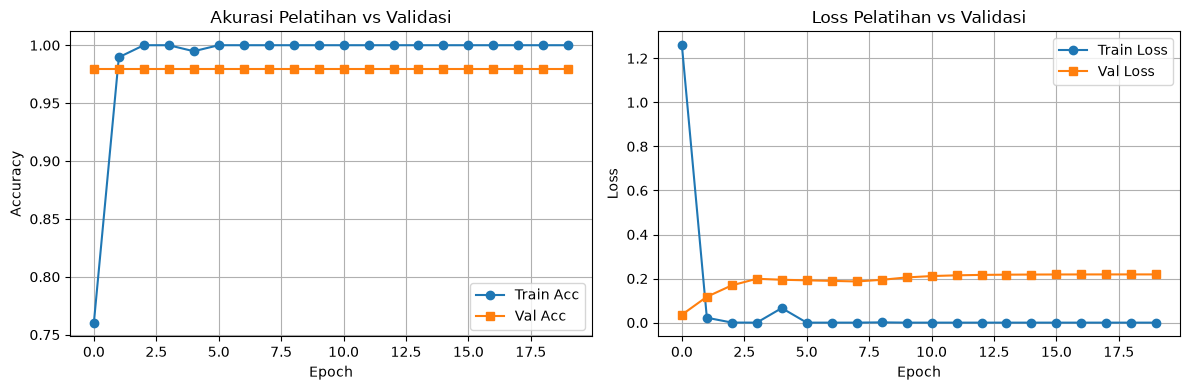

In [12]:
# Visualisasi grafik kurva akurasi dan loss pelatihan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='Train Acc', marker='o')
axes[0].plot(history.history['val_accuracy'], label='Val Acc', marker='s')
axes[0].set_title('Akurasi Pelatihan vs Validasi')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history['loss'], label='Train Loss', marker='o')
axes[1].plot(history.history['val_loss'], label='Val Loss', marker='s')
axes[1].set_title('Loss Pelatihan vs Validasi')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [13]:
# Simpan model ke format .h5 dan scaler ke format .pkl
model.save('day_night_model.h5')
print('Model berhasil disimpan: day_night_model.h5')

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print('Scaler berhasil disimpan: scaler.pkl')

Model berhasil disimpan: day_night_model.h5
Scaler berhasil disimpan: scaler.pkl


In [14]:
# Salin artefak model dan scaler ke folder deployment daynight-project
import shutil
import os

deploy_dir = 'daynight-project'
os.makedirs(deploy_dir, exist_ok=True)

shutil.copy2('day_night_model.h5', os.path.join(deploy_dir, 'day_night_model.h5'))
shutil.copy2('scaler.pkl', os.path.join(deploy_dir, 'scaler.pkl'))
print(f'Artefak model dan scaler berhasil disalin ke folder: {deploy_dir}')

Artefak model dan scaler berhasil disalin ke folder: daynight-project
